In [1]:
from pathlib import Path
import torch

print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

racine = Path("/kaggle/input")
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Trouve les dossiers qui contiennent directement des images
dossiers = {}
for p in racine.rglob("*"):
    if p.is_file() and p.suffix.lower() in EXT:
        dossiers[p.parent] = dossiers.get(p.parent, 0) + 1

total = 0
for d, n in sorted(dossiers.items()):
    print(f"{n:6d}  {d}")
    total += n
print("Total images :", total)

PyTorch : 2.11.0+cpu
GPU disponible : False
   945  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/battery
   985  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/biological
   607  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/brown-glass
   891  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/cardboard
  5325  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/clothes
   629  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/green-glass
   769  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/metal
  1050  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/paper
   865  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/plastic
  1977  /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_

In [2]:
from pathlib import Path
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42
RACINE = Path("/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification")
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

MAPPING = {
    "plastic": "PLASTIQUE",
    "paper": "PAPIER", "cardboard": "PAPIER",
    "metal": "METAL",
    "biological": "ORGANIQUE",
    "battery": "INCONNU", "brown-glass": "INCONNU", "green-glass": "INCONNU",
    "white-glass": "INCONNU", "clothes": "INCONNU", "shoes": "INCONNU", "trash": "INCONNU",
}
INCONNU_PAR_SOURCE = 128

# 1) Liste des images
morceaux = []
for dossier, classe in MAPPING.items():
    fichiers = sorted(p for p in (RACINE / dossier).iterdir() if p.suffix.lower() in EXT)
    d = pd.DataFrame({"chemin": [str(p) for p in fichiers]})
    d["classe"] = classe
    d["source"] = dossier
    if classe == "INCONNU":                      # équilibrage de la classe INCONNU
        d = d.sample(n=min(len(d), INCONNU_PAR_SOURCE), random_state=SEED)
    morceaux.append(d)
df = pd.concat(morceaux, ignore_index=True)

# 2) Suppression des images corrompues
def valide(chemin):
    try:
        with Image.open(chemin) as im:
            im.verify()
        return True
    except Exception:
        return False

avant = len(df)
df = df[df["chemin"].apply(valide)].reset_index(drop=True)
print(f"Images corrompues supprimées : {avant - len(df)}")

# 3) Découpage stratifié 70 / 15 / 15
train, temp = train_test_split(df, test_size=0.30, stratify=df["classe"], random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["classe"], random_state=SEED)

train = train.assign(split="train")
val = val.assign(split="val")
test = test.assign(split="test")
tout = pd.concat([train, val, test], ignore_index=True)

# 4) Sauvegarde et résumé
tout.to_csv("/kaggle/working/split.csv", index=False)
print("\nRépartition :")
print(pd.crosstab(tout["classe"], tout["split"], margins=True))

Images corrompues supprimées : 0

Répartition :
split      test  train  val   All
classe                           
INCONNU     135    627  134   896
METAL       115    538  116   769
ORGANIQUE   148    689  148   985
PAPIER      291   1359  291  1941
PLASTIQUE   130    606  129   865
All         819   3819  818  5456


Poids de classes :
  PLASTIQUE  1.26
  PAPIER     0.56
  METAL      1.42
  ORGANIQUE  1.11
  INCONNU    1.22

Forme d'un lot : (32, 3, 224, 224) | labels : [0, 0, 2, 3, 1, 2, 4, 2]


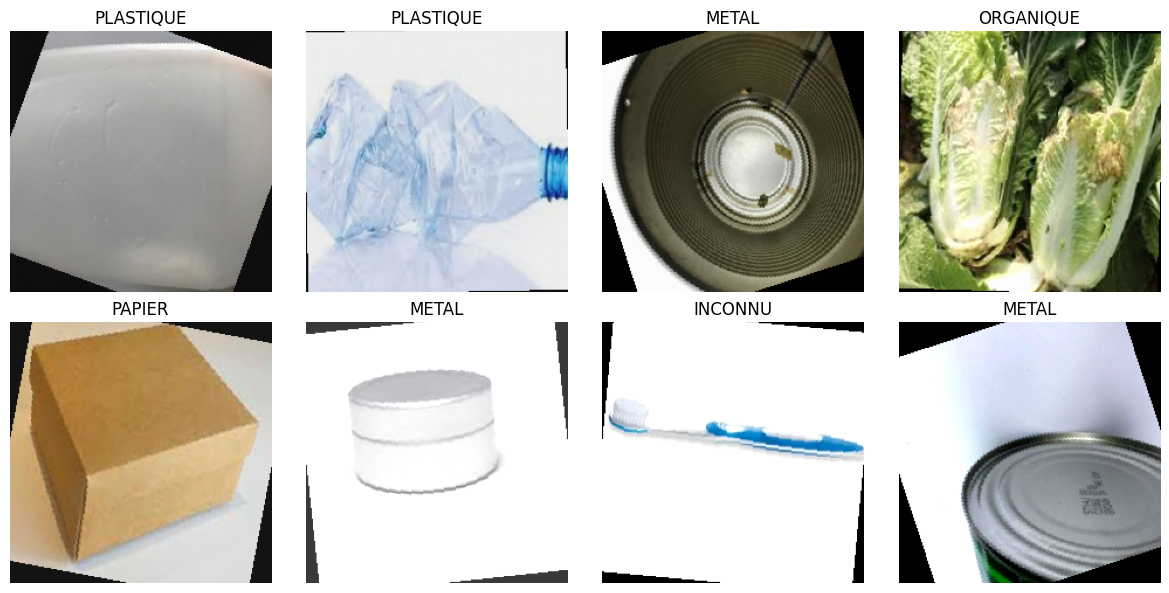

In [3]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Même ordre que l'Arduino pour les 4 premières classes (0 à 3)
CLASSES = ["PLASTIQUE", "PAPIER", "METAL", "ORGANIQUE", "INCONNU"]
CLASSE_VERS_ID = {c: i for i, c in enumerate(CLASSES)}

MOY, ETY = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # normalisation ImageNet

tf_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MOY, ETY),
])
tf_eval = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MOY, ETY),
])

class DechetsDataset(Dataset):
    def __init__(self, df, transform):
        self.chemins = df["chemin"].tolist()
        self.labels = [CLASSE_VERS_ID[c] for c in df["classe"]]
        self.transform = transform
    def __len__(self):
        return len(self.chemins)
    def __getitem__(self, i):
        img = Image.open(self.chemins[i]).convert("RGB")   # force 3 canaux
        return self.transform(img), self.labels[i]

tout = pd.read_csv("/kaggle/working/split.csv")
df_train = tout[tout["split"] == "train"]
df_val   = tout[tout["split"] == "val"]
df_test  = tout[tout["split"] == "test"]

BATCH = 32
loader_train = DataLoader(DechetsDataset(df_train, tf_train), batch_size=BATCH, shuffle=True,  num_workers=2)
loader_val   = DataLoader(DechetsDataset(df_val,   tf_eval),  batch_size=BATCH, shuffle=False, num_workers=2)
loader_test  = DataLoader(DechetsDataset(df_test,  tf_eval),  batch_size=BATCH, shuffle=False, num_workers=2)

# Poids de classes (calculés sur le train uniquement)
comptes = df_train["classe"].value_counts().reindex(CLASSES)
poids = torch.tensor((len(df_train) / (len(CLASSES) * comptes)).values, dtype=torch.float32)
print("Poids de classes :")
for c, p in zip(CLASSES, poids):
    print(f"  {c:10s} {p:.2f}")

# Vérification d'un lot
images, labels = next(iter(loader_train))
print("\nForme d'un lot :", tuple(images.shape), "| labels :", labels[:8].tolist())

# Aperçu de 8 images augmentées
mean = torch.tensor(MOY).view(3, 1, 1)
std = torch.tensor(ETY).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, lab in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASSES[lab])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
import time
import copy
import torch
import torch.nn as nn
from torchvision import models
import glob

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)



# 1) Modèle MobileNetV3-Small avec poids ImageNet chargés depuis le fichier uploadé
fichiers = glob.glob("/kaggle/input/**/mobilenet_v3_small-047dcff4.pth", recursive=True)
print("Fichier de poids :", fichiers)
model = models.mobilenet_v3_small(weights=None)
model.load_state_dict(torch.load(fichiers[0], map_location="cpu"))

# 2) Remplacer la dernière couche : 1000 classes -> 5 classes
nb_in = model.classifier[3].in_features
model.classifier[3] = nn.Linear(nb_in, len(CLASSES))
model = model.to(device)

critere = nn.CrossEntropyLoss(weight=poids.to(device))

def evaluer(loader):
    model.eval()
    perte, bons, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            sortie = model(x)
            perte += critere(sortie, y).item() * len(y)
            bons += (sortie.argmax(1) == y).sum().item()
            n += len(y)
    return perte / n, bons / n

def entrainer(nb_epoques, optimiseur, nom):
    meilleur_acc, meilleur_etat = 0.0, None
    for ep in range(1, nb_epoques + 1):
        t0 = time.time()
        model.train()
        perte_tot, bons, n = 0.0, 0, 0
        for x, y in loader_train:
            x, y = x.to(device), y.to(device)
            optimiseur.zero_grad()
            sortie = model(x)
            perte = critere(sortie, y)
            perte.backward()
            optimiseur.step()
            perte_tot += perte.item() * len(y)
            bons += (sortie.argmax(1) == y).sum().item()
            n += len(y)
        pv, av = evaluer(loader_val)
        print(f"[{nom}] époque {ep}/{nb_epoques} | train perte {perte_tot/n:.3f} acc {bons/n:.3f} "
              f"| val perte {pv:.3f} acc {av:.3f} | {time.time()-t0:.0f}s")
        if av > meilleur_acc:
            meilleur_acc, meilleur_etat = av, copy.deepcopy(model.state_dict())
    model.load_state_dict(meilleur_etat)
    return meilleur_acc

# ----- Phase 1 : on entraîne seulement la dernière couche -----
for p in model.parameters():
    p.requires_grad = False
for p in model.classifier[3].parameters():
    p.requires_grad = True

opt1 = torch.optim.Adam(model.classifier[3].parameters(), lr=1e-3)
acc1 = entrainer(3, opt1, "phase 1")
print(f"\nMeilleure accuracy validation (phase 1) : {acc1:.3f}")

Appareil : cpu
Fichier de poids : ['/kaggle/input/datasets/anouarselhami/mobilenet-weights/mobilenet_v3_small-047dcff4.pth']
[phase 1] époque 1/3 | train perte 0.868 acc 0.722 | val perte 0.505 acc 0.828 | 31s
[phase 1] époque 2/3 | train perte 0.560 acc 0.821 | val perte 0.452 acc 0.835 | 33s
[phase 1] époque 3/3 | train perte 0.501 acc 0.838 | val perte 0.429 acc 0.846 | 30s

Meilleure accuracy validation (phase 1) : 0.846


In [5]:
# ----- Phase 2 : dégel des derniers blocs -----
for p in model.parameters():
    p.requires_grad = False

# derniers blocs convolutifs + classifieur
for p in model.features[-4:].parameters():
    p.requires_grad = True
for p in model.classifier.parameters():
    p.requires_grad = True

params = [p for p in model.parameters() if p.requires_grad]
print("Paramètres entraînés :", sum(p.numel() for p in params))

opt2 = torch.optim.Adam(params, lr=1e-4)
acc2 = entrainer(6, opt2, "phase 2")
print(f"\nMeilleure accuracy validation (phase 2) : {acc2:.3f}")

# Sauvegarde du meilleur modèle
torch.save({
    "state_dict": model.state_dict(),
    "classes": CLASSES,
}, "/kaggle/working/smart_waste_model.pth")
print("Modèle sauvegardé : /kaggle/working/smart_waste_model.pth")

Paramètres entraînés : 1332461
[phase 2] époque 1/6 | train perte 0.420 acc 0.859 | val perte 0.425 acc 0.828 | 43s
[phase 2] époque 2/6 | train perte 0.330 acc 0.889 | val perte 0.318 acc 0.877 | 42s
[phase 2] époque 3/6 | train perte 0.290 acc 0.907 | val perte 0.320 acc 0.872 | 43s
[phase 2] époque 4/6 | train perte 0.243 acc 0.919 | val perte 0.276 acc 0.906 | 42s
[phase 2] époque 5/6 | train perte 0.215 acc 0.928 | val perte 0.285 acc 0.901 | 43s
[phase 2] époque 6/6 | train perte 0.180 acc 0.942 | val perte 0.265 acc 0.913 | 44s

Meilleure accuracy validation (phase 2) : 0.913
Modèle sauvegardé : /kaggle/working/smart_waste_model.pth


Accuracy test : 0.906
F1-score macro : 0.896

              precision    recall  f1-score   support

   PLASTIQUE      0.842     0.862     0.852       130
      PAPIER      0.974     0.911     0.941       291
       METAL      0.837     0.896     0.866       115
   ORGANIQUE      0.980     0.980     0.980       148
     INCONNU      0.818     0.867     0.842       135

    accuracy                          0.906       819
   macro avg      0.890     0.903     0.896       819
weighted avg      0.909     0.906     0.907       819



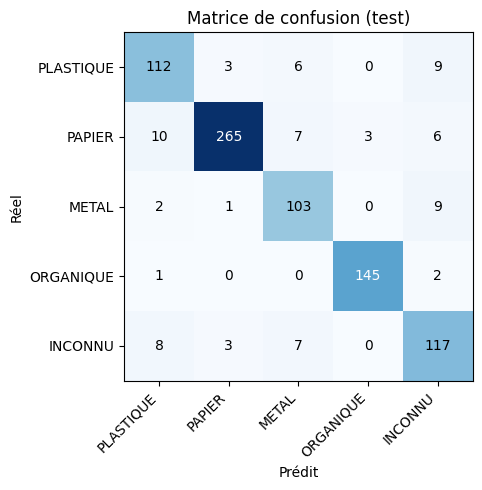


Seuil | images acceptées | accuracy sur les acceptées
 0.0  |   100.0 %       |   0.906
 0.5  |    97.6 %       |   0.919
 0.6  |    93.4 %       |   0.935
 0.7  |    88.8 %       |   0.956
 0.8  |    82.7 %       |   0.970
 0.9  |    74.5 %       |   0.987


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

model.eval()
vrais, preds, confs = [], [], []
with torch.no_grad():
    for x, y in loader_test:
        proba = torch.softmax(model(x.to(device)), dim=1).cpu()
        conf, pred = proba.max(1)
        vrais += y.tolist()
        preds += pred.tolist()
        confs += conf.tolist()

vrais, preds, confs = np.array(vrais), np.array(preds), np.array(confs)

print(f"Accuracy test : {accuracy_score(vrais, preds):.3f}")
print(f"F1-score macro : {f1_score(vrais, preds, average='macro'):.3f}\n")
print(classification_report(vrais, preds, target_names=CLASSES, digits=3))

# Matrice de confusion
cm = confusion_matrix(vrais, preds)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(5)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(5)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion (test)")
for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("/kaggle/working/matrice_confusion.png", dpi=150)
plt.show()

# Effet du seuil de confiance (celui de l'Arduino : 0.60)
print("\nSeuil | images acceptées | accuracy sur les acceptées")
for s in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    m = confs >= s
    print(f" {s:.1f}  |   {m.mean()*100:5.1f} %       |   {(vrais[m] == preds[m]).mean():.3f}")